# 3 · SPSA on simulated Tuna-17: what setup is worth running on hardware?

**Protocol** (`tfd_study/protocol.py`, the same as on hardware):
- One *chain* starts at θ = 0, the exact β = 0 state (Bell pairs). θ = 0 is a stationary point of the loss, so before the first β a batch of 8 random small kicks is evaluated and SPSA starts from the best.
- Then SPSA (the optimizer used on Tuna-17, `gibbs_tfd_reproduction/optimizers.py`) runs at β = 0.5, 1, 2, 5 in turn, each step warm-started from the previous one.
- Each loss evaluation is the all-Z and all-X circuit (4096 shots), readout-corrected. SPSA's ± pair is one batch of 4 circuits, which is one Quantum Inspire submission.
- ς per (n, p) is the re-fitted value from notebook 1.

**Backends**:
- *noiseless*: Aer with shot noise only.
- *noisy*: Aer density-matrix simulation of the Tuna-17 model fitted in notebook 2, with readout error, on the actual ladder qubits.

**Two fidelities per β step:**
- *angles*: the final angles evaluated without noise. This is the optimizer's quality.
- *device*: the state the noise model produces at those angles. This is what tomography on the device would show.

**Grid** (`python -m tfd_study.run_spsa_study`):
- main: n ∈ {2, 3, 4} × p ∈ {1, 2, 3} × {noiseless, noisy} × {20, 40, 80} SPSA steps per β × 4 seeds;
- robustness checks of the noise model;
- ς = 1.57 against the re-fitted ς.

In [1]:
import os
for v in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "1")          # before numpy: see tfd_study/__init__.py
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "tfd_study").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
from tfd_study import model, devices
from tfd_study.plotting import *
apply_style()
RES = ROOT / "tfd_study" / "results"
FIGS = ROOT / "tfd_study" / "figures"; FIGS.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)

In [2]:
chains = [json.loads(l) for l in (RES / "spsa_study.jsonl").read_text(encoding="utf-8").splitlines()]
rows = []
for c in chains:
    for st in c["steps"]:
        rows.append({k: c[k] for k in ("part", "n", "p", "s", "kind", "iters", "seed", "noise_label", "cz")}
                    | {"beta": st["beta"], "fid_angles": st["fid_angles"], "fid_device": st["fid_device"],
                       "purity": st["purity_device"]})
    rows[-1]["total_submissions"] = c["steps"][-1]["submissions"]
df = pd.DataFrame(rows)
df["total_submissions"] = df.groupby(["part", "n", "p", "s", "kind", "iters", "seed", "noise_label"])["total_submissions"].transform("max")
ce = json.loads((RES / "ceilings.json").read_text(encoding="utf-8"))
ceil = pd.DataFrame([{"n": r["n"], "p": r["p"], "target": row["target"], "beta": row["beta"],
                      "noiseless": row["fid_noiseless"], "noisy": row["fid_fit"]}
                     for r in ce["results"] for row in r["rows"]])
loss_ceil = ceil[ceil.target != "exact F"]
main = df[df.part == "main"]
print(f"{len(chains)} chains, {len(df)} β steps")

312 chains, 1248 β steps


## Fidelity versus hardware cost

Each point is one setup: size n, depth p (colour) and SPSA steps per β (labelled 20/40/80). It is the mean over 4 seeds of the measured-on-device fidelity, averaged over β ∈ {0.5, 1, 2, 5}. The x-axis is what one chain costs in Quantum Inspire submissions, excluding final tomography. Dashed lines: the noisy ceiling, i.e. the best angles of our loss run through the same noise model.

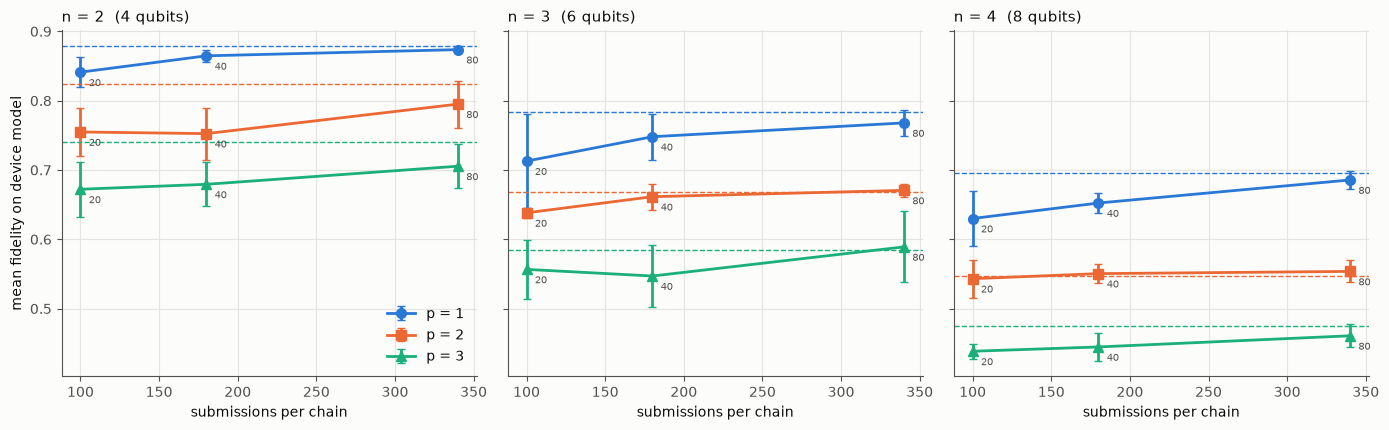

In [3]:
noisy = main[main.kind == "noisy"]
agg = (noisy.groupby(["n", "p", "iters", "seed"]).agg(F=("fid_device", "mean"), subs=("total_submissions", "max"))
            .groupby(["n", "p", "iters"]).agg(F=("F", "mean"), F_std=("F", "std"), subs=("subs", "mean")).reset_index())
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, n in zip(axes, (2, 3, 4)):
    for p in (1, 2, 3):
        a = agg[(agg.n == n) & (agg.p == p)].sort_values("subs")
        ax.errorbar(a.subs, a.F, yerr=a.F_std, color=LAYER_COLORS[p], marker=LAYER_MARKERS[p], capsize=3, label=f"p = {p}")
        for _, r in a.iterrows():
            ax.annotate(f"{int(r.iters)}", (r.subs, r.F), textcoords="offset points", xytext=(6, -10), fontsize=7, color=INK_DIM)
        lc = loss_ceil[(loss_ceil.n == n) & (loss_ceil.p == p)].noisy.mean()
        ax.axhline(lc, color=LAYER_COLORS[p], ls="--", lw=1)
    ax.set_xlabel("submissions per chain"); ax.set_title(f"n = {n}  ({2 * n} qubits)")
axes[0].set_ylabel("mean fidelity on device model")
axes[0].legend(loc="lower right")
fig.tight_layout(); fig.savefig(FIGS / "spsa_fidelity_vs_cost.png", dpi=130, bbox_inches="tight"); plt.show()

## Per β: SPSA against the ceilings

Mean ± std over seeds at 80 SPSA steps per β. Solid: SPSA on the noisy model. Light: SPSA with shot noise only. Dashed: noiseless ceiling of our loss. Dotted: the same angles on the noise model.

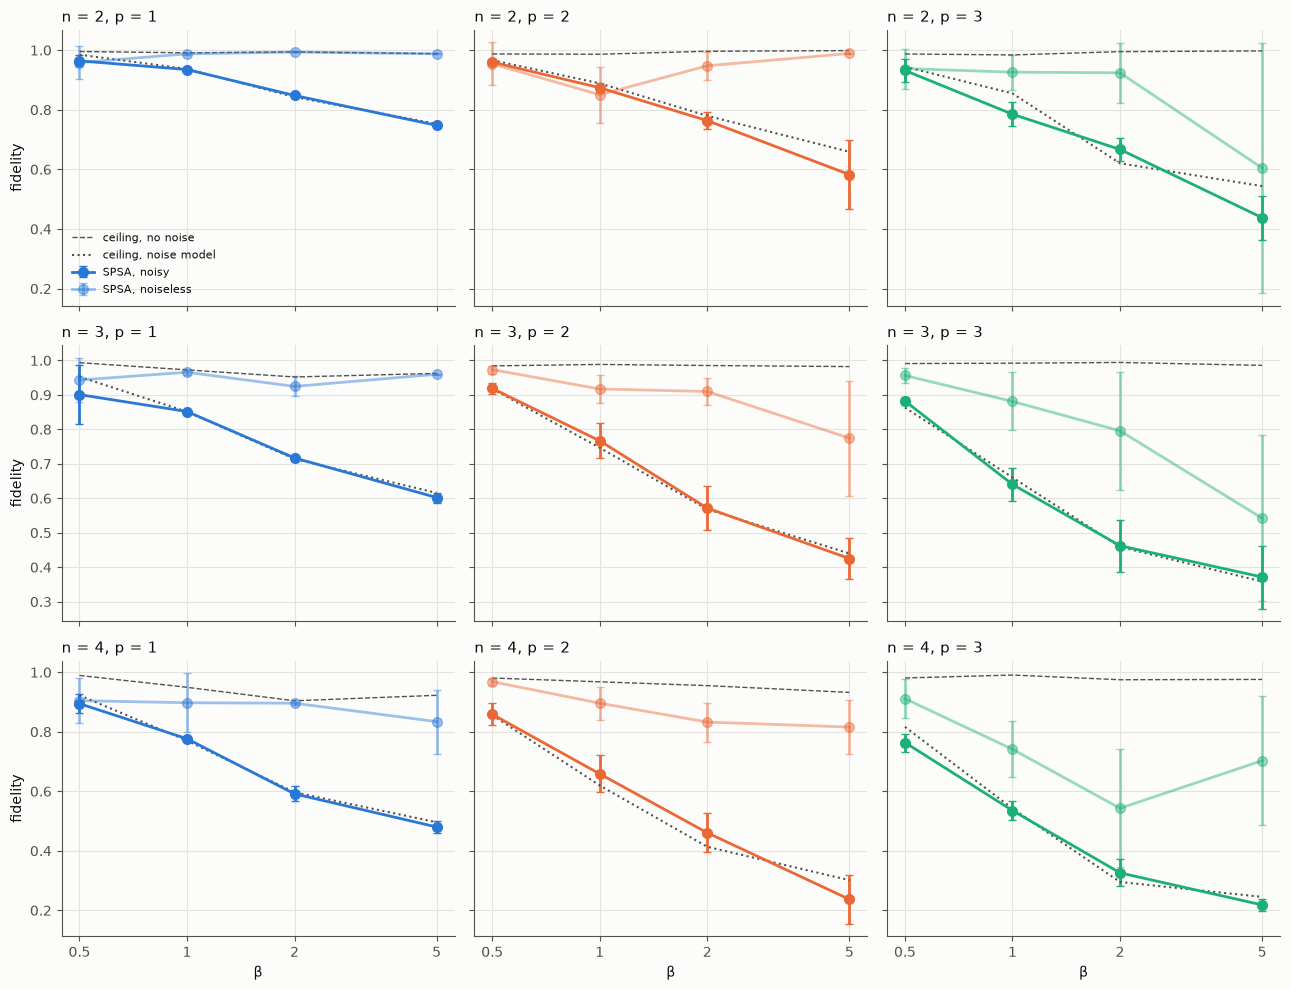

In [4]:
it = 80
fig, axes = plt.subplots(3, 3, figsize=(13, 10), sharex=True, sharey="row")
for i, n in enumerate((2, 3, 4)):
    for j, p in enumerate((1, 2, 3)):
        ax = axes[i, j]; col = LAYER_COLORS[p]
        for kind, alpha in (("noisy", 1.0), ("noiseless", 0.45)):
            g = main[(main.n == n) & (main.p == p) & (main.kind == kind) & (main.iters == it)].groupby("beta").fid_device
            ax.errorbar(g.mean().index, g.mean(), yerr=g.std(), color=col, alpha=alpha, marker="o", capsize=3,
                        label=f"SPSA, {kind}")
        lc = loss_ceil[(loss_ceil.n == n) & (loss_ceil.p == p)].sort_values("beta")
        ax.plot(lc.beta, lc.noiseless, color=INK_DIM, ls="--", lw=1, label="ceiling, no noise")
        ax.plot(lc.beta, lc.noisy, color=INK_DIM, ls=":", lw=1.5, label="ceiling, noise model")
        ax.set_xscale("log"); ax.set_xticks(ce["betas"], [f"{b:g}" for b in ce["betas"]]); ax.xaxis.set_minor_locator(plt.NullLocator())
        ax.set_title(f"n = {n}, p = {p}")
        if i == 2: ax.set_xlabel("β")
        if j == 0: ax.set_ylabel("fidelity")
axes[0, 0].legend(fontsize=8, loc="lower left")
fig.tight_layout(); fig.savefig(FIGS / "spsa_per_beta.png", dpi=130, bbox_inches="tight"); plt.show()

## Is SPSA the bottleneck? Angle quality against steps

Fidelity of the found angles *without* noise, mean over β and seeds. Where this is close to the noiseless ceiling, more SPSA steps cannot help: the device noise is what limits the result.

In [5]:
q = (main.groupby(["n", "p", "kind", "iters"]).fid_angles.mean().unstack(["kind", "iters"]).round(3))
q.insert(0, "ceiling", loss_ceil.groupby(["n", "p"]).noiseless.mean().round(3))
q

kind  ceiling noiseless                noisy              
iters                20     40     80     20     40     80
n p                                                       
2 1     0.992     0.943  0.974  0.982  0.948  0.977  0.983
  2     0.992     0.888  0.815  0.935  0.875  0.898  0.939
  3     0.991     0.882  0.867  0.848  0.852  0.844  0.891
3 1     0.970     0.838  0.918  0.948  0.887  0.919  0.947
  2     0.985     0.843  0.876  0.894  0.829  0.864  0.880
  3     0.991     0.671  0.816  0.794  0.803  0.757  0.853
4 1     0.941     0.859  0.889  0.883  0.841  0.878  0.915
  2     0.959     0.767  0.801  0.878  0.846  0.819  0.794
  3     0.981     0.585  0.704  0.725  0.701  0.780  0.816

## Robustness: does the ranking survive a different noise model?

Mean device fidelity over β and seeds at 40 steps, for gate noise ×0.5, ×1 (fitted) and ×1.5, and for the depolarizing-only model that fits the Tuna-17 data equally well.

In [6]:
rob = pd.concat([df[(df.part == "robustness")],
                 main[(main.kind == "noisy") & (main.iters == 40) & (main.p <= 2)].assign(noise_label="fit")])
rt = rob.groupby(["n", "p", "noise_label"]).fid_device.mean().unstack("noise_label")
rt = rt[["x0.5", "fit", "x1.5", "depolarizing-only"]].round(3)
rt

noise_label   x0.5    fit   x1.5  depolarizing-only
n p                                                
2 1          0.920  0.865  0.811              0.875
  2          0.827  0.752  0.738              0.774
3 1          0.845  0.748  0.683              0.752
  2          0.767  0.661  0.594              0.652
4 1          0.769  0.652  0.582              0.663
  2          0.672  0.550  0.502              0.548

## Does the re-fitted ς matter under noise? (p = 2, 40 steps)

In [7]:
vs = df[df.part == "varsigma"].groupby(["n", "s"]).agg(F_device=("fid_device", "mean"), F_angles=("fid_angles", "mean"),
                                                       worst_device=("fid_device", "min")).round(3)
vs

F_device  F_angles  worst_device
n s                                     
2 1.30     0.752     0.898         0.554
  1.57     0.780     0.939         0.566
3 1.30     0.661     0.864         0.399
  1.57     0.649     0.883         0.375
4 1.30     0.550     0.819         0.277
  1.57     0.559     0.834         0.221

## Ranking of hardware setups

Noisy model. Per setup:
- mean and worst-β device fidelity (mean over seeds);
- seed-to-seed spread;
- cost of one chain;
- cost of the final tomographies: 3ⁿ settings + 2 calibration circuits per β, in submissions of 5 circuits.

In [8]:
import math
g = noisy.groupby(["n", "p", "iters"])
rank = pd.DataFrame({
    "F mean": g.fid_device.mean(),
    "F worst β": noisy.groupby(["n", "p", "iters", "beta"]).fid_device.mean().groupby(["n", "p", "iters"]).min(),
    "seed spread": noisy.groupby(["n", "p", "iters", "seed"]).fid_device.mean().groupby(["n", "p", "iters"]).std(),
    "chain submissions": g.total_submissions.mean(),
}).reset_index()
rank["tomography submissions (4 β)"] = rank.n.map(lambda n: 4 * math.ceil((3 ** n + 2) / 5))
rank["CZ"] = rank.apply(lambda r: noisy[(noisy.n == r.n) & (noisy.p == r.p)].cz.iloc[0], axis=1)
rank = rank.round(3).sort_values(["n", "F mean"], ascending=[True, False])
rank.groupby("n").head(4).set_index(["n", "p", "iters"])

F mean  F worst β  seed spread  chain submissions  \
n p iters                                                      
2 1 80      0.874      0.748        0.003              340.0   
    40      0.865      0.722        0.009              180.0   
    20      0.841      0.716        0.022              100.0   
  2 80      0.795      0.583        0.034              340.0   
3 1 80      0.768      0.602        0.019              340.0   
    40      0.748      0.601        0.033              180.0   
    20      0.713      0.583        0.068              100.0   
  2 80      0.671      0.425        0.009              340.0   
4 1 80      0.686      0.480        0.013              340.0   
    40      0.652      0.480        0.014              180.0   
    20      0.630      0.419        0.040              100.0   
  2 80      0.554      0.237        0.016              340.0   

           tomography submissions (4 β)  CZ  
n p iters                                    
2 1 80                               12  10  
    40                               12  10  
    20                               12  10  
  2 80                               12  18  
3 1 80                               24  17  
    40                               24  17  
    20                               24  17  
  2 80                               24  31  
4 1 80                               68  24  
    40                               68  24  
    20                               68  24  
  2 80                               68  44

## Conclusions (SPSA on the Tuna-17 model)

1. **One layer wins at every size and budget.** Device fidelity at 80 SPSA steps (mean over β and seeds), p = 1 / 2 / 3:
   - 2+2: 0.874 / 0.795 / 0.705
   - 3+3: 0.768 / 0.671 / 0.589
   - 4+4: 0.686 / 0.554 / 0.461

   The ranking is the same with gate noise ×0.5, ×1.5 and with the depolarizing-only model. This is the noise-model result of notebook 2, now with a real optimizer.
2. **At p = 1, SPSA reaches the noisy ceiling.** The ceiling (best angles of our loss, run through the noise model) is 0.879 / 0.783 / 0.696 for 2+2 / 3+3 / 4+4.
   - 80 steps per β: within 0.005–0.015 of it.
   - 40 steps: 0.014–0.044 below.
   - 20 steps: 0.04–0.07 below, and with more spread between seeds (3+3: std 0.068 at 20 steps, 0.033 at 40, 0.019 at 80).
3. **Noise does not mislead the optimizer.** The angles SPSA finds on the noisy model are as good, evaluated without noise, as those it finds with shot noise only. For example, 3+3 with p = 1 at 80 steps: 0.947 vs 0.948. What the device shows is limited by the noise acting on good angles, not by bad angles.
4. **ς hardly matters once noise is on.** At p = 2, the re-fitted 1.3 and the paper's 1.57 give the same device fidelity within seed scatter (2+2: 0.75 vs 0.78; 3+3: 0.66 vs 0.65; 4+4: 0.55 vs 0.56). With one layer the best ς is 1.5–1.57 anyway.
5. **Cost.** A chain over 4 β is 100 / 180 / 340 submissions at 20 / 40 / 80 SPSA steps, plus the tomographies: 3ⁿ settings, i.e. 1 / 6 / 17 submissions per tomography for n = 2 / 3 / 4 qubits per side. At about 33 submissions per hour, one 80-step chain alone is about 10 h. A one-night run therefore has to trade steps against replicas. That trade-off is notebook 4.